# 🚀 Модуль 2. Урок 2. Агрегация данных, GROUP BY и разница с HAVING

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_02_sql/lesson_02_aggregations_group_by_having.ipynb)

## 📌 Бизнес-контекст и методология
Агрегация данных — ядро формирования продуктовых метрик: выручки (Revenue), среднего чека (AOV), объема продаж (GMV) и маржинальности (Gross Margin).
Ключевая ошибка начинающих аналитиков — непонимание различия между `WHERE` и `HAVING`:
- `WHERE` фильтрует сырые транзакции **ДО** объединения в группы
- `HAVING` фильтрует рассчитанные агрегированные метрики **ПОСЛЕ** выполнения `GROUP BY`

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

db_path = ensure_dataset("ecommerce.db")
conn = sqlite3.connect(db_path)
print(f"🟢 Подключение к базе данных успешно установлено: {db_path}")

🟢 Подключение к базе данных успешно установлено: course\datasets\ecommerce.db


## 🔍 Разбор механики и демонстрация на реальных данных
Рассчитаем ключевые показатели эффективности (KPI) по категориям товаров: совокупную выручку, валовую прибыль и средний чек позиции.

In [2]:
# Демонстрация: Агрегация продаж по категориям товаров
query_agg = """
SELECT 
    p.category,
    COUNT(DISTINCT o.order_id) as total_orders,
    ROUND(SUM(oi.total_amount), 2) as total_revenue,
    ROUND(SUM(oi.total_amount - (p.cost * oi.quantity)), 2) as total_profit,
    ROUND(AVG(oi.total_amount), 2) as avg_item_revenue
FROM order_items oi
JOIN products p ON oi.product_id = p.product_id
JOIN orders o ON oi.order_id = o.order_id
WHERE o.status = 'Completed'
GROUP BY p.category
HAVING total_revenue > 500000
ORDER BY total_revenue DESC;
"""
df_agg = pd.read_sql_query(query_agg, conn)
display(df_agg)

,category,total_orders,total_revenue,total_profit,avg_item_revenue
0,Electronics,876,740144.93,355880.58,734.27
1,Fashion,727,719947.13,276579.96,886.63
2,Beauty,608,602967.07,189638.74,917.76
3,Home & Kitchen,694,547300.48,230086.58,693.66


## 📊 Визуализация бизнес-кейса: Выручка vs Маржинальная прибыль по категориям
Сравним категории товаров по объему сгенерированной выручки и валовой маржи (Gross Margin %), выделив самые прибыльные драйверы бизнеса.

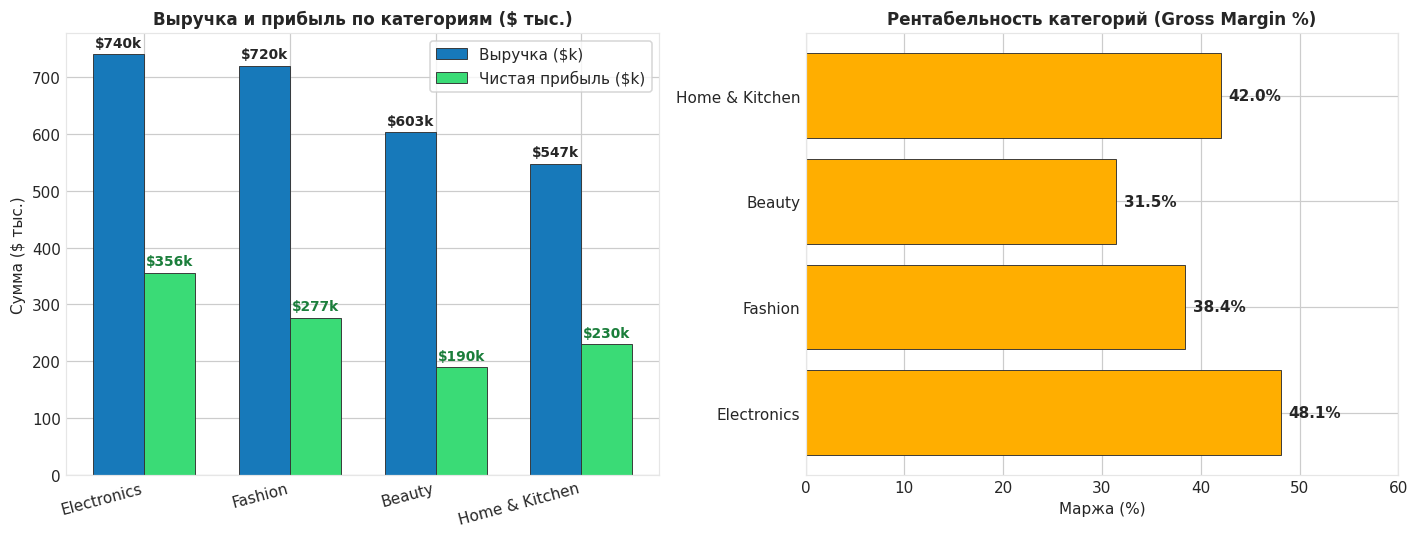

In [3]:
# Расчет маржинальности и построение 2-панельного дашборда
df_agg['margin_pct'] = (df_agg['total_profit'] / df_agg['total_revenue']) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=110)

# Панель 1: Выручка и Прибыль (в тыс. $)
x = np.arange(len(df_agg['category']))
width = 0.35

rects1 = ax1.bar(x - width/2, df_agg['total_revenue'] / 1000, width, label='Выручка ($k)', color=PRIMARY, edgecolor='#333333', linewidth=0.6)
rects2 = ax1.bar(x + width/2, df_agg['total_profit'] / 1000, width, label='Чистая прибыль ($k)', color=SUCCESS, edgecolor='#333333', linewidth=0.6)

ax1.set_title("Выручка и прибыль по категориям ($ тыс.)", fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(df_agg['category'], rotation=15, ha='right')
ax1.legend(frameon=True, facecolor='#ffffff')
ax1.set_ylabel("Сумма ($ тыс.)")

for r in rects1:
    h = r.get_height()
    ax1.annotate(f"${h:.0f}k", xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

for r in rects2:
    h = r.get_height()
    ax1.annotate(f"${h:.0f}k", xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#1b7e3b')

# Панель 2: Процент маржинальности
bars = ax2.barh(df_agg['category'], df_agg['margin_pct'], color=WARNING, edgecolor='#333333', linewidth=0.6)
ax2.set_title("Рентабельность категорий (Gross Margin %)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Маржа (%)")
ax2.set_xlim(0, 60)

for b in bars:
    w = b.get_width()
    ax2.annotate(f"{w:.1f}%", xy=(w, b.get_y() + b.get_height()/2), xytext=(5, 0),
                 textcoords="offset points", ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Поиск постоянных клиентов (Repeat Buyers)
Найдите клиентов, которые совершили более 2 завершенных заказов (`status = 'Completed'`). Выведите их `customer_id` и количество заказов `orders_count`.

In [4]:
### ВАШ КОД ЗДЕСЬ
query_repeat = """
SELECT 
    customer_id,
    COUNT(order_id) as orders_count
FROM orders
WHERE status = 'Completed'
GROUP BY customer_id
HAVING COUNT(order_id) > 2
ORDER BY orders_count DESC;
"""

df_repeat = pd.read_sql_query(query_repeat, conn)
print(f"Всего постоянных покупателей (>2 заказов): {len(df_repeat)}")
display(df_repeat.head(6))

assert not df_repeat.empty, "Список повторных покупателей не должен быть пустым"
assert (df_repeat['orders_count'] > 2).all(), "Все клиенты должны иметь более 2 заказов"
print("✅ Тест успешно пройден: агрегация и фильтрация HAVING работают корректно!")

Всего постоянных покупателей (>2 заказов): 251


,customer_id,orders_count
0,1022,11
1,869,11
2,377,11
3,24,11
4,116,10
5,1110,9


✅ Тест успешно пройден: агрегация и фильтрация HAVING работают корректно!


### 💡 Executive Takeaway: Оптимизация GROUP BY
1. СУБД выполняет `GROUP BY` через хэширование или сортировку. Чем меньше строк доходит до группировки, тем быстрее работает запрос.
2. Всегда переносите фильтры по неагрегированным полям в блок `WHERE`, не допуская их попадания в `HAVING`.